In [1]:
from backend.utils.gmsh_function import *
from backend.utils.file_path import *
from backend.src.radiation_algorithm.radiation_algorithm import *

from loop_antenna_mesh import create_loop_antenna_mesh

from backend.cma.cma_algorithm import cma_algorithm
from backend.cma.cma_frequency_sweep import cma_frequency_sweep
from backend.cma.modal_current import ModalCurrent
from backend.cma.modal_farfield import compute_modal_farfield
from backend.cma.modal_visualizer import ModalVisualizer
from backend.cma.modal_significance import modal_significance

In [2]:
name = "loop_antenna"
path = setup_save_file_paths(name)

In [3]:
# --- Geometry parameters (identical to characteristic_modes_AToM.m) ---
pixel_size = 0.04                           # [m] edge length of one pixel
n_rows = 6                                  # Mask rows    -> y dimension
n_cols = 12                                 # Mask columns -> x dimension
border_pixels = 1                           # frame thickness, from Mask(2:end-1, 2:end-1) = 0

initial_mesh_size = pixel_size * 0.7           # target triangle edge length, adjust as needed

# print values
print(f"Pixel size: {pixel_size} m")
print(f"Number of rows: {n_rows}")
print(f"Number of columns: {n_cols}")
print(f"Border pixels: {border_pixels}")
print(f"Initial mesh size: {initial_mesh_size} m")

Pixel size: 0.04 m
Number of rows: 6
Number of columns: 12
Border pixels: 1
Initial mesh size: 0.027999999999999997 m


In [ ]:
gmsh.initialize()

gmsh.model.add("loop_antenna")

setup_performance_config()

create_loop_antenna_mesh(pixel_size, n_rows, n_cols, border_pixels)

generate_and_save_mesh(path, initial_mesh_size)

# gmsh.fltk.run()

# Quick summary
n_nodes = len(gmsh.model.mesh.getNodes()[0])
n_tris = len(gmsh.model.mesh.getElementsByType(2)[0])
print(f"Strip width: {pixel_size * 1000:.0f} mm")
print(f"Nodes: {n_nodes}, Triangles: {n_tris}")

gmsh.finalize()

[PERFORMANCE] Gmsh configured to utilize 16 threads.
Geometry file saved in data/gmsh_files/loop_antenna.brep successfully
--- Starting Mesh Optimization (Dim: 2) ---
--- Optimization Complete ---
Mesh file saved in data/gmsh_files/loop_antenna.msh successfully
Strip width: 40 mm
Nodes: 150, Triangles: 204


In [5]:
# 1. Eigenvalues over a frequency range
n_modes_cma = 6

freq_start_cma = 100e6
freq_stop_cma = 300e6

sweep_data = cma_frequency_sweep(path, freq_start_cma, freq_stop_cma, n_points=11, n_modes=n_modes_cma)

Mesh ready: 150 points, 204 triangles, 258 edges -- regenerated from data/gmsh_files/loop_antenna.msh

Assembling Z(f) for 11 frequencies (258x258 edges) on GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) -- geometry reused across the whole sweep...
[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (258x258 edges, 11 frequencies).
Z(f) assembly done in 4.7 s (0.431 s/frequency amortised)

Step 1/11 |   100.00 MHz | lambda: -26.690, -81.982, 147.828, -5170.238, -6231.366, 102470.347
Step 2/11 |   120.00 MHz | lambda: -14.161, -46.088, 87.869, -2065.541, -2502.860, 41718.754
Step 3/11 |   140.00 MHz | lambda: -8.216, -27.960, 57.070, -947.845, -1156.025, 19613.056
Step 4/11 |   160.00 MHz | lambda: -4.549, -17.650, 39.583, -481.601, -591.702, 10259.336
Step 5/11 |   180.00 MHz | lambda: -2.698, -11.443, 28.884, -264.103, -327.118, 5832.177
Step 6/11 |   200.00 MHz | lambda: -1.440, -7.354, 21.957, -153.712, -192.131, 3548.348
Step 7/1

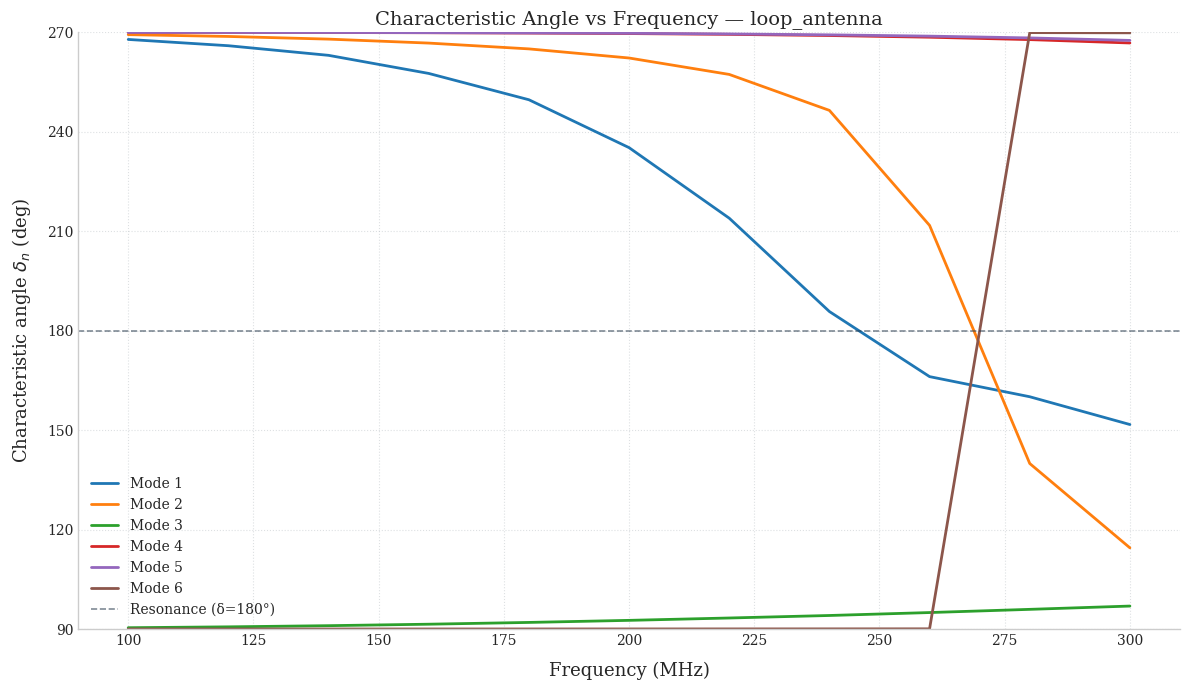

In [6]:
# 2. Characteristic angle delta_n = 180 - atan(lambda_n), for the first 6 modes.
#    Read this one first: delta stays inside (90, 270) deg so every mode is visible
#    at the same scale, whereas lambda spans ~1e5 here and would flatten all but one
#    curve. A mode resonates where it crosses 180 deg; the steeper the crossing, the
#    narrower its band (higher Q).
ModalVisualizer.plot_characteristic_angle_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

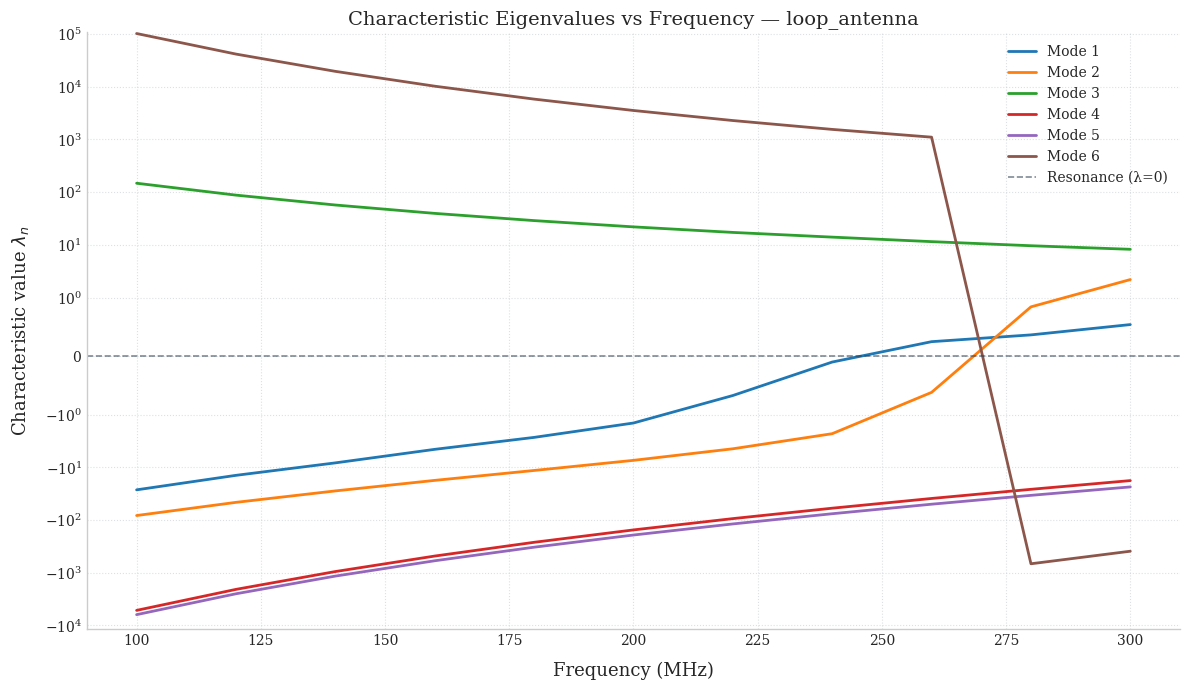

In [7]:
# 3. Raw eigenvalues lambda_n for the first 6 modes.
#    y axis is symlog by default: linear within +/-1 so the zero crossings (the
#    resonances) stay undistorted, logarithmic beyond so the far-from-resonance
#    modes reaching ~1e5 remain readable. Pass yscale='linear' for the raw view.
ModalVisualizer.plot_eigenvalues_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

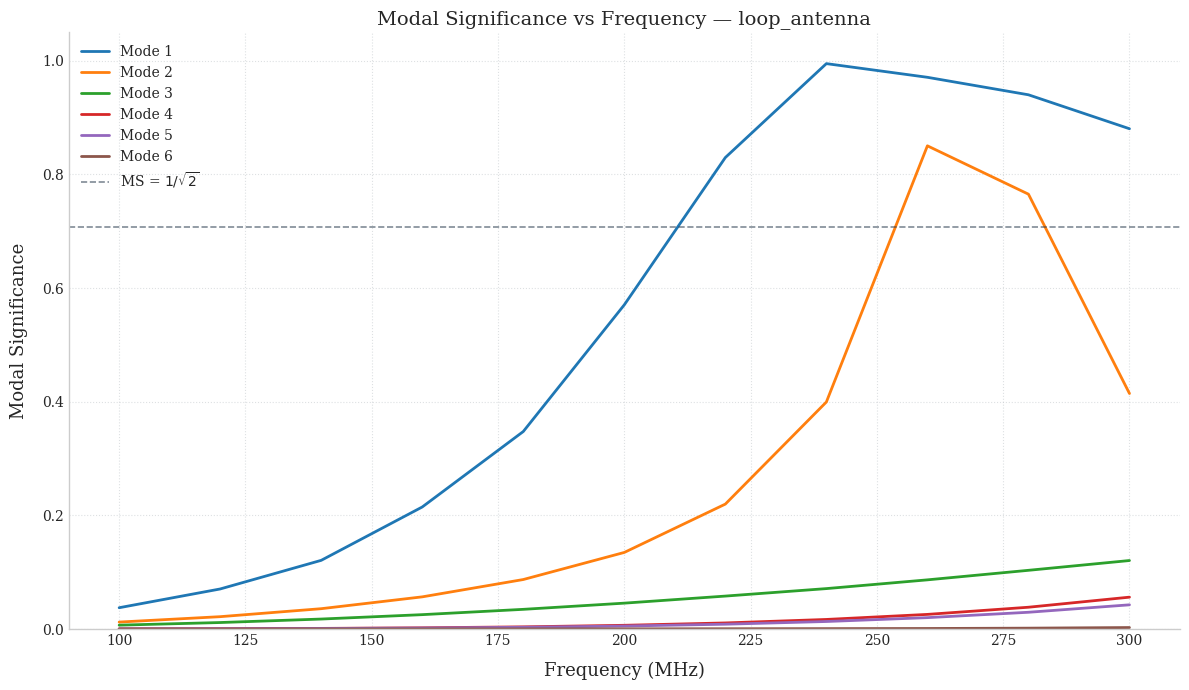

In [8]:
# 4. Modal Significance for the first 6 modes
ModalVisualizer.plot_modal_significance(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

In [9]:
# 5. Characteristic currents of the first 6 modes, at the design frequency
frequency = 200e6
modal_data = cma_algorithm(path, frequency=frequency, n_modes=n_modes_cma, show=True)

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (258x258 edges).
CMA: 6 modes computed at f = 0.2000 GHz
  λ range: [-192.1042, 3548.3221]


In [10]:
# 6. Far-field pattern of the first 6 modes, at the same design frequency
_, triangles, edges, _vecteurs_rho = DataManager_rwg2.load_data(path.mat_mesh2)
freq_cma, _omega, _mu, _epsilon, light_speed_c, eta, _Z = DataManager_rwg3.load_data(path.mat_impedance)

for n in range(n_modes_cma):
    J_n = modal_data.eigenvectors[:, n]
    sphere_points, sphere_triangles, gain_db, directivity_max = compute_modal_farfield(
        triangles, edges, J_n, freq_cma, light_speed_c, eta)
    print(f"Mode {n + 1} (lambda = {modal_data.eigenvalues[n]:.4f}): "
          f"peak directivity = {10 * np.log10(directivity_max):.2f} dBi")
    fig = ModalVisualizer.plot_mode_farfield(sphere_points, sphere_triangles, gain_db,
                                              mode_index=n, eigenvalue=modal_data.eigenvalues[n])
    fig.show()

Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 1 (lambda = -1.4272): peak directivity = 2.31 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 2 (lambda = -7.3065): peak directivity = 3.45 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 3 (lambda = 22.0086): peak directivity = 2.67 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 4 (lambda = -153.7536): peak directivity = 4.06 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 5 (lambda = -192.1042): peak directivity = 2.90 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 6 (lambda = 3548.3221): peak directivity = 6.03 dBi


## Diagnostic : cohérence numérique de la matrice Z à 200 MHz

Le sweep ci-dessus a besoin d'une régularisation de plus en plus grande à chaque fréquence
(`eps_adapt` croissant, R negatif de plus en plus loin de 0) -- pas juste du bruit flottant
ponctuel. Avant d'aller plus loin, on vérifie directement la matrice Z assemblée à 200 MHz :

1. **Réciprocité** : `max|Z - Z^T| / max|Z|` doit être ~0 (précision machine) -- un MoM de
   Galerkin correct donne toujours une matrice Z parfaitement symétrique.
2. **R = Re(Z) semi-définie positive** : `min eig(R)` doit être ~0 aux erreurs numériques
   près -- cohérent avec une structure PEC sans perte (puissance rayonnée toujours >= 0).

In [11]:
from backend.rwg.rwg2 import DataManager_rwg2
from backend.rwg.rwg3 import calculate_z_matrice
from backend.cma.z_matrix_diagnostics import diagnose_z_matrix

points_diag, triangles_diag, edges_diag, _vecteurs_rho_diag = DataManager_rwg2.load_data(path.mat_mesh2)

diag_frequency = 200e6
_omega_diag, _mu_diag, _epsilon_diag, _c_diag, _eta_diag, Z_diag = calculate_z_matrice(
    points_diag, triangles_diag, edges_diag, diag_frequency)

_ = diagnose_z_matrix(Z_diag, frequency=diag_frequency, label=path.name)

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (258x258 edges).

Z-matrix diagnostics -- loop_antenna @ 200.00 MHz
Reciprocity   : max|Z-Z^T| = 2.866e-07  max|Z| = 1.443e+00  -> relative asymmetry = 1.986e-07  [WARNING: not reciprocal]
R = Re(Z) PSD : min eig(R) = -4.719e-16 Ohm  (relative to ||R||_F/N = -1.922e-11)  [OK, ~0 within noise]
